In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
RAW = Path(os.environ.get('ASTRO320W_DATA', '/Users/gracedavis/2026-10-19_before_submission_cleanup'))
BIAS = Path(os.environ.get('ASTRO320W_BIAS', '/Users/gracedavis/ASTRO 320W/04_Data/A/Bias_Frames'))


In [2]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import astroalign as aa

folder = str(RAW / 'EXERCISE C-2')

files = [
    f"{folder}/CCD Image {i}.fit"
    for i in range(10, 15)
]

print("Number of images:", len(files))

for f in files:
    print(f)

Number of images: 5
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/CCD Image 10.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/CCD Image 11.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/CCD Image 12.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/CCD Image 13.fit
/Users/gracedavis/2026-10-19_before_submission_cleanup/EXERCISE C-2/CCD Image 14.fit


In [3]:
reference = fits.getdata(files[0]).astype(float)

aligned_images = [reference]

print("CCD Image 10: reference")

for i, filename in enumerate(files[1:], start=2):

    image = fits.getdata(filename).astype(float)

    try:
        aligned, footprint = aa.register(
            image,
            reference
        )

        aligned_images.append(aligned)

        print(f"CCD Image {i}: aligned")

    except Exception as e:
        print(f"CCD Image {i}: FAILED")
        print(e)

aligned_images = np.array(aligned_images)

print("\nSuccessfully aligned:", len(aligned_images))

CCD Image 10: reference


CCD Image 2: aligned


CCD Image 3: aligned


CCD Image 4: aligned


CCD Image 5: aligned

Successfully aligned: 5


In [4]:
master_ccd = np.nanmedian(aligned_images, axis=0)

print("Stacked image shape:", master_ccd.shape)

Stacked image shape: (3056, 3056)


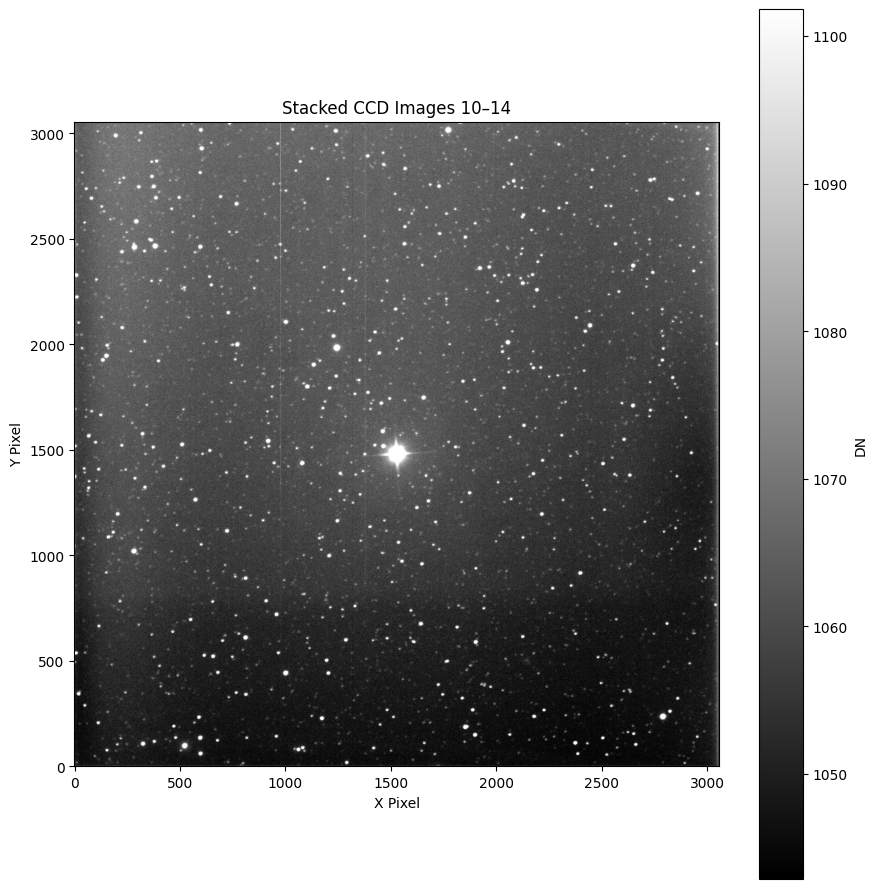

In [5]:
vmin = np.nanpercentile(master_ccd, 5)
vmax = np.nanpercentile(master_ccd, 99.5)

plt.figure(figsize=(9, 9))

plt.imshow(
    master_ccd,
    origin="lower",
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)

plt.colorbar(label="DN")
plt.xlabel("X Pixel")
plt.ylabel("Y Pixel")
plt.title("Stacked CCD Images 10–14")

plt.tight_layout()
plt.show()

Quadratic best focus: 16117.5 microns
Measured minimum FWHM: 9.75 pixels
Focus at measured minimum: 16000 microns
15000: mean=12.740, SD=nan
15500: mean=10.720, SD=nan
16000: mean=10.215, SD=0.658
16500: mean=10.300, SD=nan
17000: mean=11.717, SD=0.627


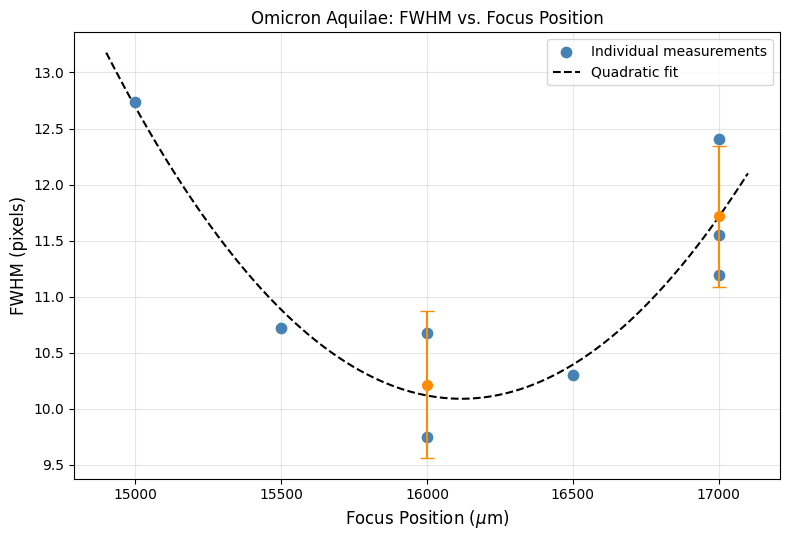

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# Focus positions from observing log (microns)
focus = np.array([
    17000, 17000, 17000, 16500,
    16000, 16000, 15500, 15000
])

# FWHM measurements from AstroImageJ (pixels)
fwhm = np.array([
    11.55, 12.41, 11.19, 10.30,
    9.75, 10.68, 10.72, 12.74
])

# Calculate mean and standard deviation
unique_focus = np.sort(np.unique(focus))

mean_fwhm = []
std_fwhm = []

for pos in unique_focus:
    values = fwhm[focus == pos]
    mean_fwhm.append(np.mean(values))

    if len(values) > 1:
        std_fwhm.append(np.std(values, ddof=1))
    else:
        std_fwhm.append(np.nan)

mean_fwhm = np.array(mean_fwhm)
std_fwhm = np.array(std_fwhm)

# Quadratic fit to all measurements
# Center x values to improve numerical stability
x = (focus - 16000) / 1000
coeff = np.polyfit(x, fwhm, 2)

x_fit = np.linspace(-1.1, 1.1, 300)
y_fit = np.polyval(coeff, x_fit)
focus_fit = 16000 + 1000 * x_fit

# Plot
plt.figure(figsize=(8, 5.5))

plt.scatter(
    focus, fwhm,
    color="steelblue",
    s=55,
    label="Individual measurements",
    zorder=3
)

# Plot means and scatter at repeated focus positions
for pos, mean, std in zip(
    unique_focus, mean_fwhm, std_fwhm
):
    if np.isfinite(std):
        plt.errorbar(
            pos, mean, yerr=std,
            fmt="o", color="darkorange",
            capsize=5, markersize=7,
            zorder=4
        )

plt.plot(
    focus_fit, y_fit,
    color="black", linestyle="--",
    label="Quadratic fit"
)

# Best focus from the quadratic model
a, b, c = coeff
if a > 0:
    best_focus = 16000 - 1000 * b / (2 * a)
    print(f"Quadratic best focus: {best_focus:.1f} microns")

print("Measured minimum FWHM:",
      np.min(fwhm), "pixels")
print("Focus at measured minimum:",
      focus[np.argmin(fwhm)], "microns")

for pos, mean, std in zip(
    unique_focus, mean_fwhm, std_fwhm
):
    print(f"{pos}: mean={mean:.3f}, SD={std:.3f}")

plt.xlabel("Focus Position ($\\mu$m)", fontsize=12)
plt.ylabel("FWHM (pixels)", fontsize=12)
plt.title("Omicron Aquilae: FWHM vs. Focus Position")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("fwhm_vs_focus.pdf", bbox_inches="tight")
plt.show()


Mean count rate: 199592.39 DN/s
Standard deviation: 13691.27 DN/s
Relative scatter: 6.86%
Mean reported relative error: 0.107%
Image  1:  203469.93 DN/s, deviation =  +1.94%
Image  2:  214460.47 DN/s, deviation =  +7.45%
Image  3:  201686.32 DN/s, deviation =  +1.05%
Image  4:  206217.33 DN/s, deviation =  +3.32%
Image  5:  206521.57 DN/s, deviation =  +3.47%
Image  6:  223866.43 DN/s, deviation = +12.16%
Image  7:  185466.11 DN/s, deviation =  -7.08%
Image  8:  194289.94 DN/s, deviation =  -2.66%
Image  9:  187244.66 DN/s, deviation =  -6.19%
Image 10:  184442.49 DN/s, deviation =  -7.59%
Image 11:  198451.63 DN/s, deviation =  -0.57%
Image 12:  184109.14 DN/s, deviation =  -7.76%
Image 13:  193222.86 DN/s, deviation =  -3.19%
Image 14:  224559.38 DN/s, deviation = +12.51%
Image 15:  185877.63 DN/s, deviation =  -6.87%


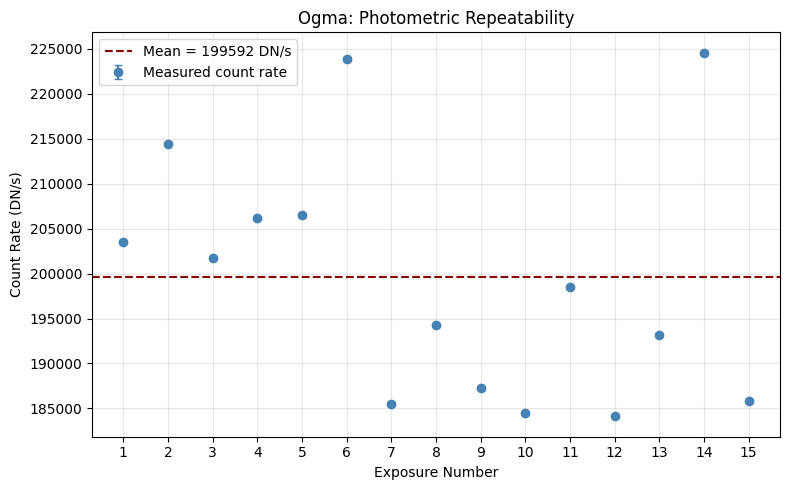

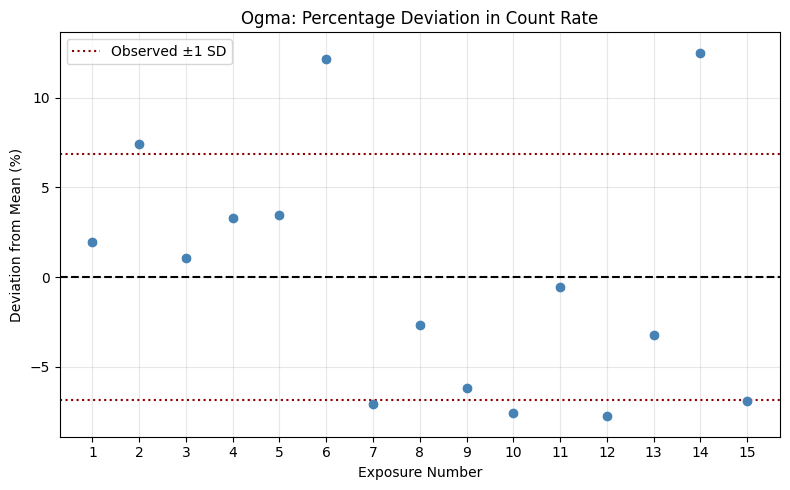

In [7]:

import numpy as np
import matplotlib.pyplot as plt

# Ogma: 15 consecutive 8-second exposures
image = np.arange(1, 16)
exposure_time = 8.0

# Background-subtracted counts from AstroImageJ (DN)
counts = np.array([
    1627759.435, 1715683.799, 1613490.583,
    1649738.664, 1652172.584, 1790931.408,
    1483728.904, 1554319.499, 1497957.282,
    1475539.941, 1587613.006, 1472873.097,
    1545782.894, 1796475.038, 1487021.056
])

# AstroImageJ source errors (DN)
counts_error = np.array([
    1717.825, 1743.171, 1713.426,
    1724.207, 1725.219, 1764.898,
    1672.878, 1693.942, 1677.301,
    1670.701, 1703.966, 1670.457,
    1692.204, 1764.908, 1674.747
])

# Count rates and uncertainties
rate = counts / exposure_time
rate_error = counts_error / exposure_time

mean_rate = np.mean(rate)
std_rate = np.std(rate, ddof=1)

# Percentage deviations from the mean
percent_dev = 100 * (rate - mean_rate) / mean_rate
percent_error = 100 * rate_error / mean_rate

print(f"Mean count rate: {mean_rate:.2f} DN/s")
print(f"Standard deviation: {std_rate:.2f} DN/s")
print(f"Relative scatter: {100*std_rate/mean_rate:.2f}%")
print(f"Mean reported relative error: "
      f"{np.mean(counts_error/counts)*100:.3f}%")

for i, r, d in zip(image, rate, percent_dev):
    print(f"Image {i:2d}: {r:10.2f} DN/s, "
          f"deviation = {d:+6.2f}%")

# Figure 1: Count rate vs. image number
plt.figure(figsize=(8, 5))

plt.errorbar(
    image, rate, yerr=rate_error,
    fmt="o", color="steelblue",
    capsize=3, label="Measured count rate"
)

plt.axhline(
    mean_rate, color="darkred", linestyle="--",
    label=f"Mean = {mean_rate:.0f} DN/s"
)

plt.xlabel("Exposure Number")
plt.ylabel("Count Rate (DN/s)")
plt.title("Ogma: Photometric Repeatability")
plt.xticks(image)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("ogma_repeatability.pdf")
plt.show()

# Figure 2: Percentage deviations
plt.figure(figsize=(8, 5))

plt.errorbar(
    image, percent_dev, yerr=percent_error,
    fmt="o", color="steelblue", capsize=3
)

plt.axhline(0, color="black", linestyle="--")
plt.axhline(
    100 * std_rate / mean_rate,
    color="darkred", linestyle=":",
    label="Observed ±1 SD"
)
plt.axhline(
    -100 * std_rate / mean_rate,
    color="darkred", linestyle=":"
)

plt.xlabel("Exposure Number")
plt.ylabel("Deviation from Mean (%)")
plt.title("Ogma: Percentage Deviation in Count Rate")
plt.xticks(image)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("ogma_percent_deviation.pdf")
plt.show()
